# Super cool experiment

# Super cool experiment

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [6]:
path = "/media/external/test3/maria_e/CRC/CRC/Xenium/output-XETG00213__0021489__Region_1__20240125__150400"
sdata = spatialdata_io.xenium(path)

INFO     reading                                                                                                   
         /media/external/test3/maria_e/CRC/CRC/Xenium/output-XETG00213__0021489__Region_1__20240125__150400/cell_fe
         ature_matrix.h5                                                                                           


In [7]:
outpath = "/media/sergio/Meninges/troutpy/xenium_crc.zarr"
sdata.write(outpath)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_crc.zarr                                                            


## Import packages

In [2]:
outpath = "/media/sergio/Meninges/troutpy/xenium_crc.zarr"
sdata=sd.read_zarr(outpath)

In [5]:
print(sdata.coordinate_systems)
#print(sdata['table'].coordinate_system)  # coordinate system of the table

['global']


In [8]:
sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/xenium_crc.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 51122, 48455), (1, 25561, 24227), (1, 12780, 12113), (1, 6390, 6056), (1, 3195, 3028)
│     └── 'morphology_mip': DataTree[cyx] (1, 51122, 48455), (1, 25561, 24227), (1, 12780, 12113), (1, 6390, 6056), (1, 3195, 3028)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (51122, 48455), (25561, 24227), (12780, 12113), (6390, 6056), (3195, 3028)
│     └── 'nucleus_labels': DataTree[yx] (51122, 48455), (25561, 24227), (12780, 12113), (6390, 6056), (3195, 3028)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (469838, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (469838, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (469838, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (469838, 322)
with coordinate syst

In [10]:
from spatialdata.transformations import get_transformation

# Get spatial coordinates (Nx2 array)
local_coords = sdata['table'].obsm['spatial']

print(sdata.coordinate_systems)
print(
#    get_transformation(sdata["table"]),
    get_transformation(sdata["morphology_focus"]),
    get_transformation(sdata["nucleus_boundaries"]),
)



['global']
Identity  Scale (x, y)
    [4.70588235 4.70588235]


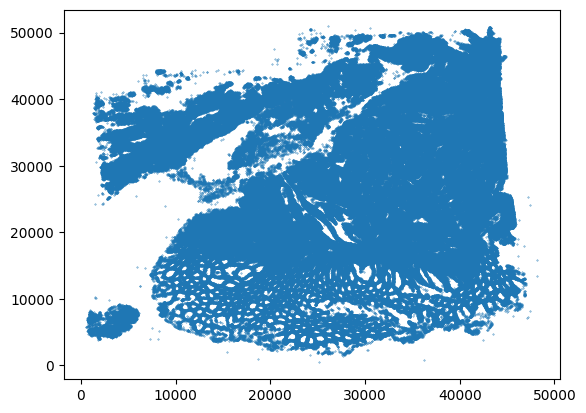

In [16]:
spat=[g[0]*4.7 for g in sdata['table'].obsm['spatial']]
spat2=[g[1]*4.7 for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.1)

In [17]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[25000, 25000],
    max_coordinate=[35000, 35000],
    target_coordinate_system="global",
)


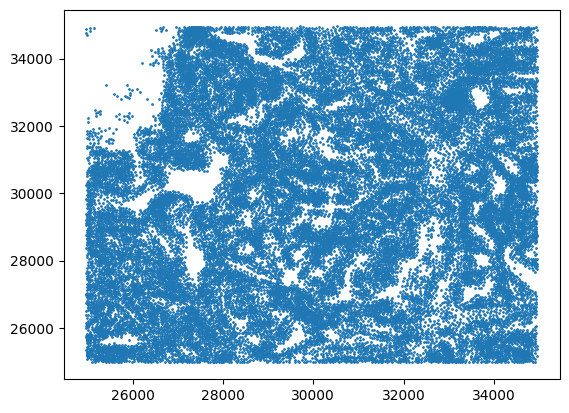

In [18]:
spat=[g[0]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
spat2=[g[1]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [19]:
cropped_sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
│     └── 'morphology_mip': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
│     └── 'nucleus_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (31909, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (31495, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (31717, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (31495, 322)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), cell_lab

In [20]:
sdata=cropped_sdata

In [21]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
│     └── 'morphology_mip': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
│     └── 'nucleus_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (31909, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (31495, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (31717, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (31495, 322)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), cell_lab

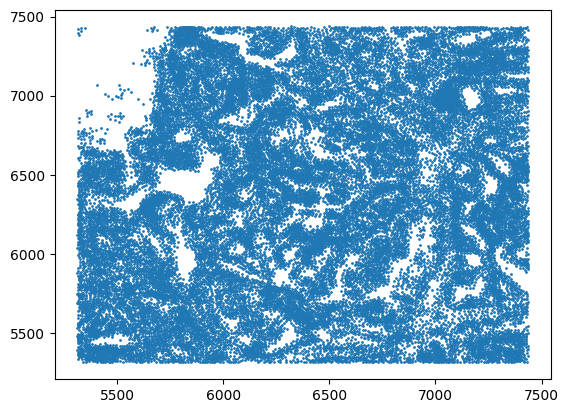

In [22]:
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [23]:
transcripts=sdata['transcripts'].compute()
transcripts.reset_index(drop=True,inplace=True)
sdata['transcripts']=sd.models.PointsModel.parse(transcripts)

# Cell type identification

In [24]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
│     └── 'morphology_mip': DataTree[cyx] (1, 10000, 10000), (1, 5000, 5000), (1, 2500, 2499), (1, 1250, 1249), (1, 625, 625)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
│     └── 'nucleus_labels': DataTree[yx] (10000, 10000), (5000, 5000), (2500, 2499), (1250, 1249), (625, 625)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (31909, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (31495, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (31717, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (31495, 322)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), cell_lab

(31495, 322)


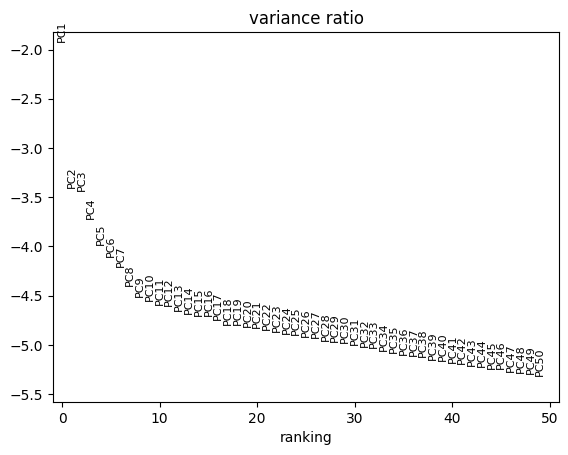

2025-04-09 08:15:23.089482: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-09 08:15:23.107892: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744179323.126530 1665570 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744179323.131350 1665570 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744179323.144134 1665570 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

(30235, 322)


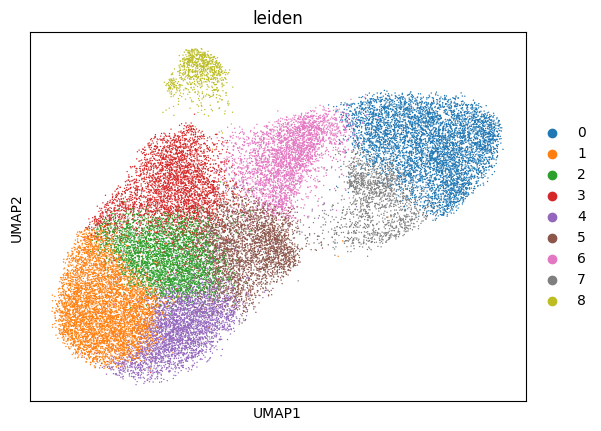

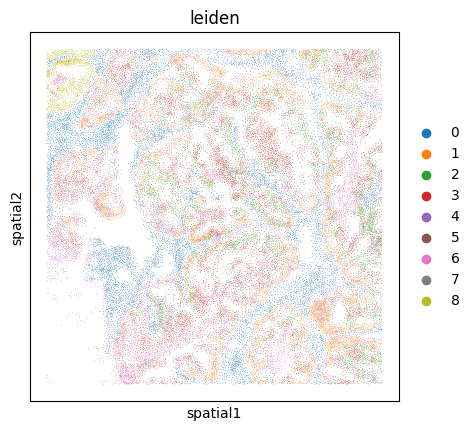

In [25]:
adata = sdata["table"]
#sc.pp.subsample(adata,0.1)
print(adata.shape)
adata.raw = adata.copy()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")
sc.pl.umap(adata,color='leiden')
sc.pl.spatial(adata,color='leiden',spot_size=5)

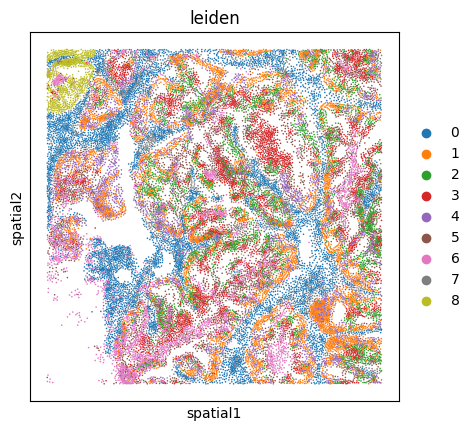

In [33]:
sc.pl.spatial(adata,color='leiden',spot_size=10)

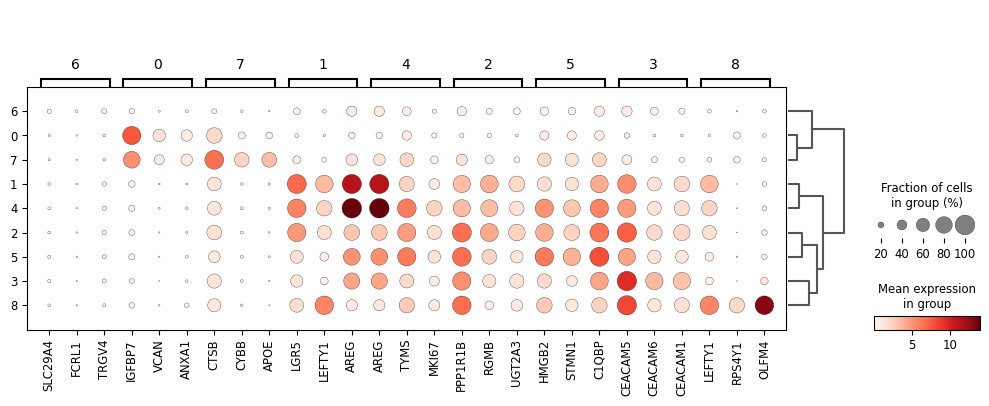

In [27]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups_dotplot(adata,groupby='leiden',n_genes=3)

## Segmentation free analysis

In [28]:
troutpy.pp.segmentation_free_sainsc(sdata,binsize=3,celltype_key='leiden',
                                    background_filter=0.4,gaussian_kernel_key=2.0,
                                    n_threads=16)

In [29]:
trans=sdata['transcripts'].compute()
trans['overlaps_cell']=trans['cell_id']!='UNASSIGNED'
sdata.points["transcripts"] = sd.models.PointsModel.parse(trans)

In [30]:
troutpy.pp.define_extracellular(
    sdata,layer = "transcripts",method= "sainsc",
    unassigned_tag = "UNASSIGNED",
    copy = False, percentile_threshold = 10)

Cosine similarity threshold for extracellular definition: 0.553398072719574


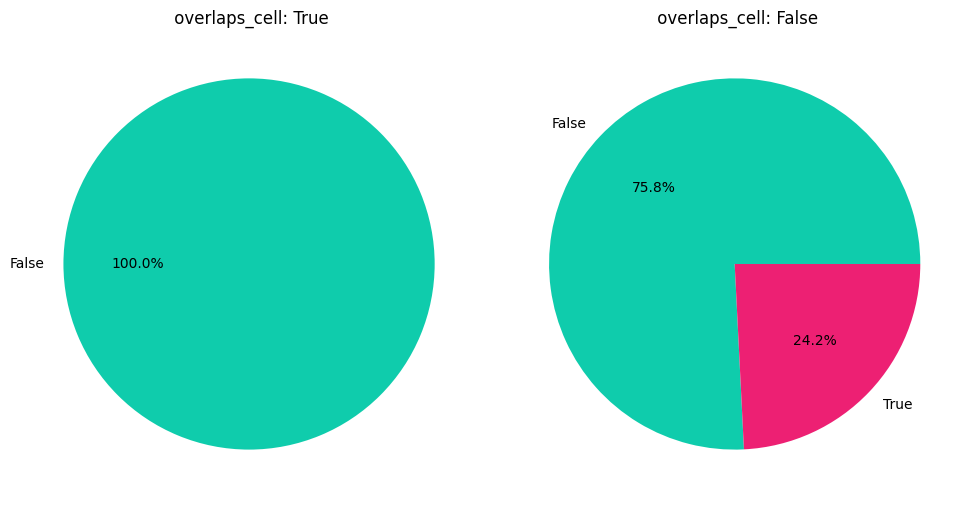

In [31]:
troutpy.pl.pie(sdata, groupby="extracellular",group_key='overlaps_cell')

<Figure size 500x500 with 0 Axes>

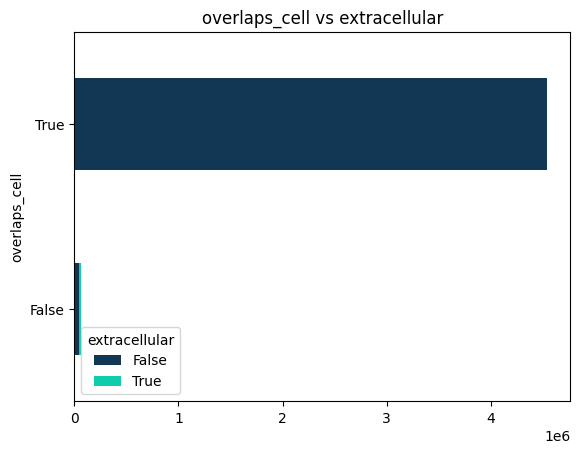

In [32]:
troutpy.pl.crosstab(sdata,yvar='extracellular',xvar='overlaps_cell',normalize=False, cmap='troutpy',kind='barh',stacked=True)

In [37]:
sdata['transcripts']

,x,y,z,feature_name,cell_id,qv,fov_name,overlaps_nucleus,transcript_id,nucleus_distance,xy,closest_cell_type,cosine_similarity,assignment_score,overlaps_cell,match_cell_signature,extracellular
npartitions=1,,,,,,,,,,,,,,,,,
0,float32,float32,float32,category[known],string,float32,string,uint8,uint64,float32,string,string,float64,float64,bool[pyarrow],bool,bool[pyarrow]
4600229,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


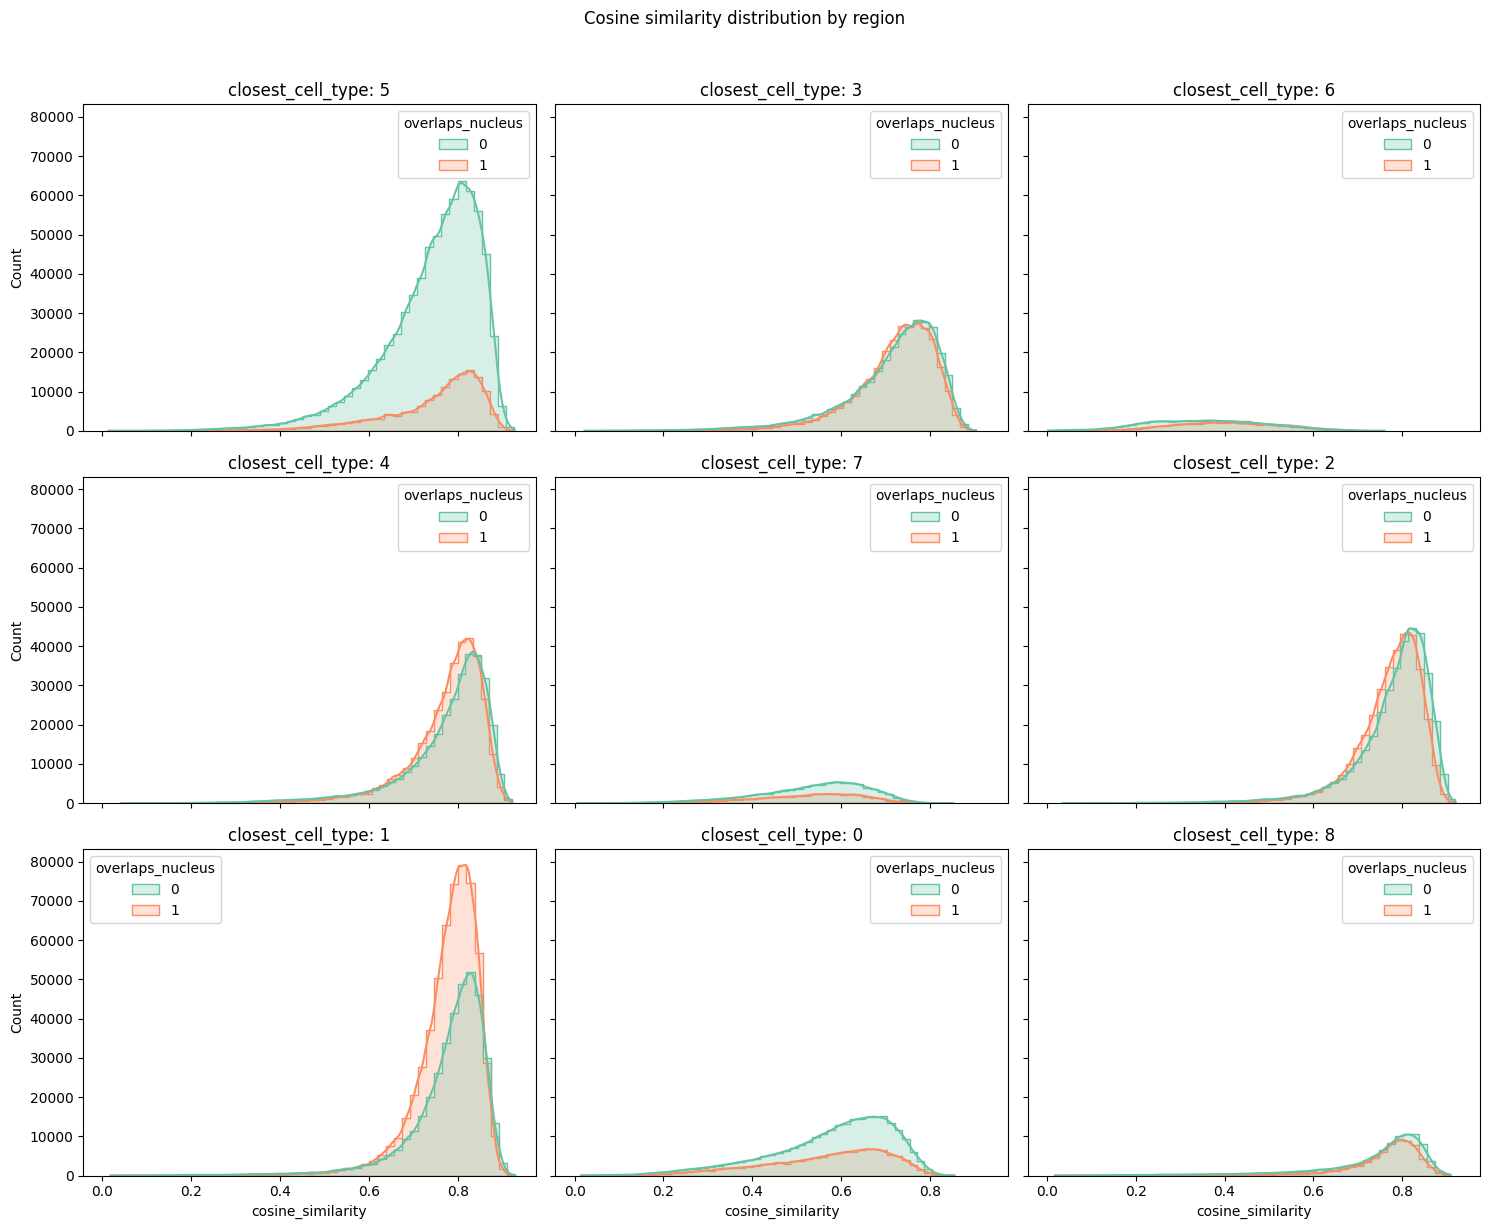

In [38]:
troutpy.pl.histogram(
    sdata,
    x="cosine_similarity",
    hue="overlaps_nucleus",
    group_key="closest_cell_type",
    title="Cosine similarity distribution by region",
    save=False,
    bins=50,
    kde=True,
    palette="Set2"
)


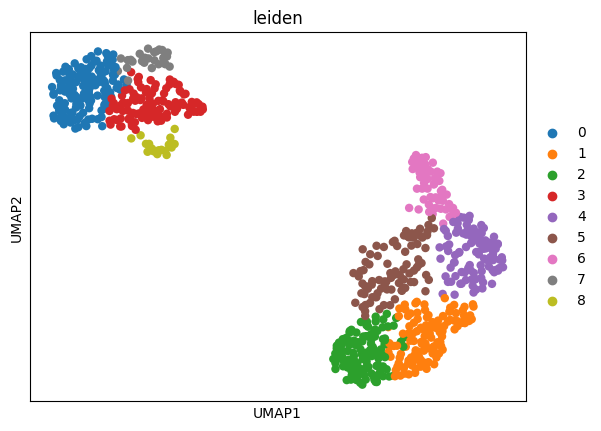

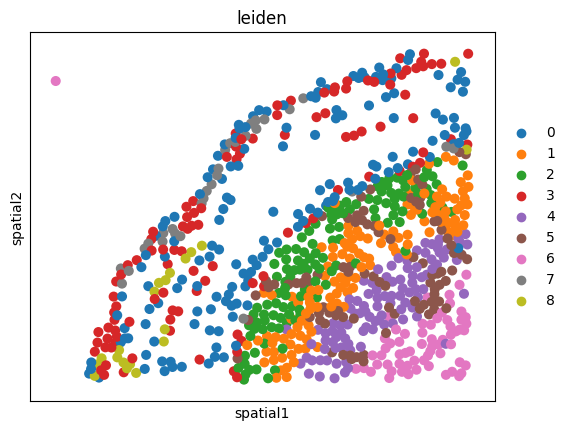

In [13]:
sc.pl.umap(adata,color='leiden')
sc.pl.spatial(adata,color='leiden',spot_size=10)

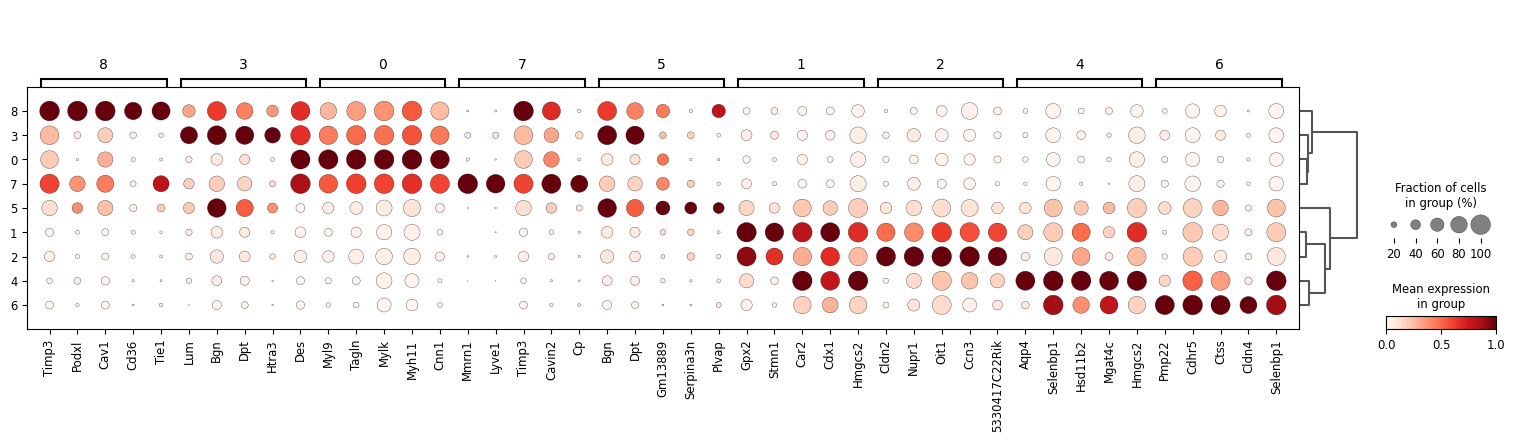

In [14]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=5)

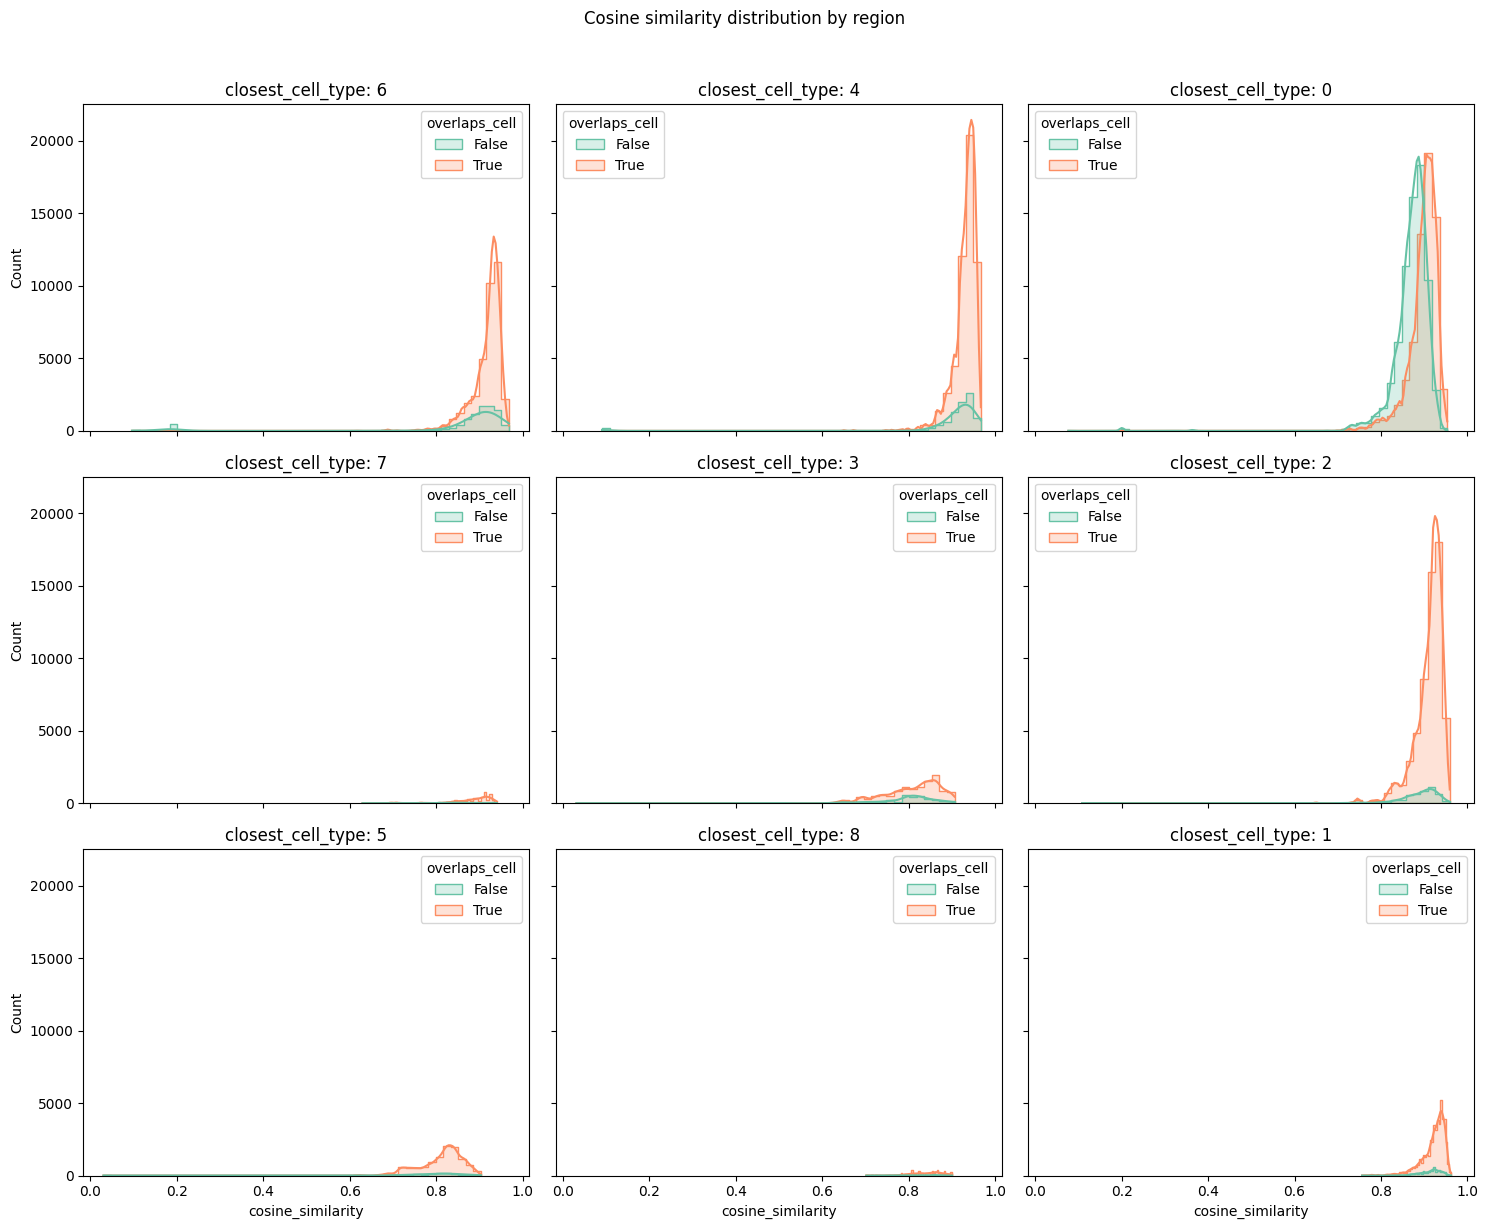

In [15]:
troutpy.pl.histogram(
    sdata,
    x="cosine_similarity",
    hue="overlaps_cell",
    group_key="closest_cell_type",
    title="Cosine similarity distribution by region",
    save=False,
    bins=50,
    kde=True,
    palette="Set2"
)


## Quantify exRNa

In [39]:
import numpy as np
gen=np.unique(sdata['transcripts']['feature_name'].compute())
control_codewords = [g for g in gen if 'Con' in g ]

troutpy.tl.quantify_overexpression(
    sdata,layer="transcripts",codeword_key="feature_name",
    control_codewords=control_codewords,gene_key="feature_name",
    percentile_threshold=99.99)

Added 'xrna_metadata' table with 541 unique genes to the SpatialData object.


False


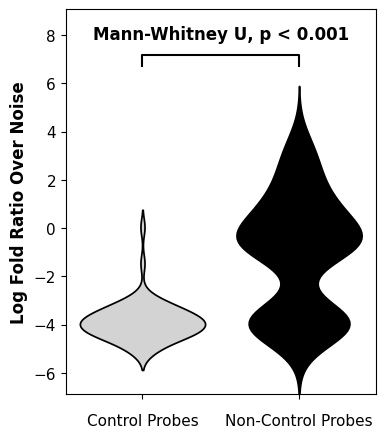

In [40]:
troutpy.pl.logfoldratio_over_noise(sdata,test_method="auto")

In [41]:
import pandas as pd
pd.crosstab(sdata['xrna_metadata'].var['p_value_Poisson']<0.0005,sdata['xrna_metadata'].var['control_probe'])

control_probe,False,True
p_value_Poisson,,
False,21,6
True,459,55


# Clustering extracellular

Computing KNN-based signatures: 100%|██████████| 15494/15494 [00:00<00:00, 330696.78it/s]


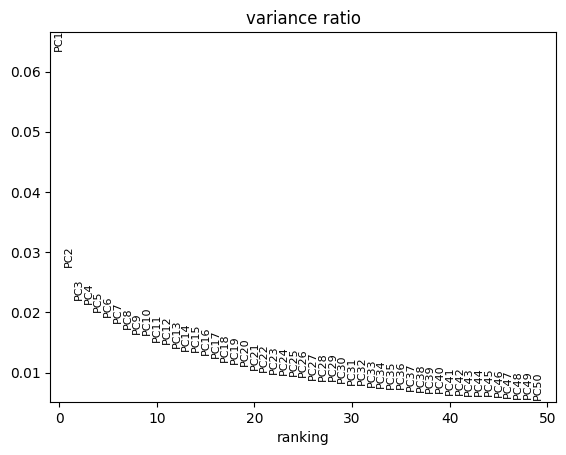

In [ ]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,
    layer = "transcripts",
    gene_key = "feature_name",
    method = "knn", knn_k=30,
)
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50)
# neighbors
sc.pp.neighbors(adata,n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.7)
sc.pl.umap(adata,color='leiden',palette='Accent',s=100)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

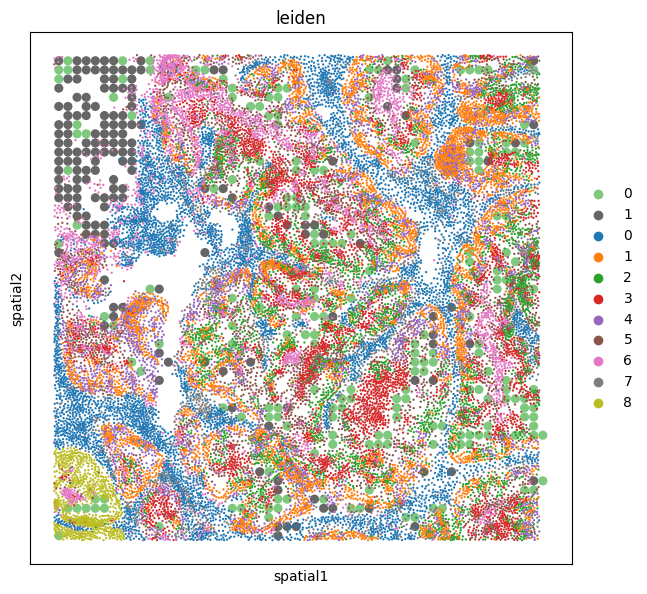

In [52]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=40,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=10,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

# Test diffussion

In [ ]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=0)

In [25]:
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
from sklearn.neighbors import KDTree
from spatialdata import SpatialData
from tqdm import tqdm

def compute_source_score(
    sdata: SpatialData,
    layer: str = "transcripts",
    gene_key: str = "feature_name",
    coord_keys: list = None,  # type: ignore
    lambda_decay: float = 0.1,
    copy: bool = False,
    celltype_key: str = "cell type",
):
    """
    Computes the probabilities of each extracellular transcript originating from a specific cell.

    Parameters
    ----------
    sdata
        The input spatial data object.
    layer
        The layer in `sdata.points` containing the transcript data. Default is 'transcripts'.
    gene_key
        Column name in the transcript data representing gene identifiers. Default is 'feature_name'.
    xcoord, ycoord
        Column names for spatial coordinates of transcripts and cell centroids.
    lambda_decay
        The exponential decay factor for distances.
    copy
        If True, returns a modified copy of the SpatialData object.
    celltype_key
        Key for cell type annotations in the cell table.

    Returns
    -------
    sdata
        Updated SpatialData object with source scores added in sdata.tables['source_score'], including distance to closest cell
    """
    if coord_keys is None:
        coord_keys = ["x", "y"]
    xcoord = coord_keys[0]
    ycoord = coord_keys[1]

    transcripts = sdata.points[layer].compute()
    cells = sdata["table"].to_df()
    coord_cells = sdata["table"].obsm["spatial"]
    cell_types = sdata["table"].obs[celltype_key]
    all_cell_types = cell_types.unique()

    # Ensure necessary columns exist
    required_cols = [xcoord, ycoord, gene_key]
    for col in required_cols:
        if col not in transcripts.columns and col not in cells.columns:
            raise ValueError(f"Required column '{col}' is missing.")

    # Filter for extracellular transcripts only
    extracellular_transcripts = transcripts[transcripts["extracellular"]]
    probabilities_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=all_cell_types, dtype=float)

    # Precompute KDTree for all cell coordinates
    closet_cell_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=["closest_cell", "closest_celltype", "distance"])

    # Process each gene
    for gene in tqdm(cells.columns.unique(), desc="Processing genes"):
        # Filter transcripts and cells for the current gene
        gene_transcripts = extracellular_transcripts[extracellular_transcripts[gene_key] == gene]

        gene_mask = cells[gene] > 0  # Mask for cells expressing the gene
        if not gene_mask.any() or gene_transcripts.empty:
            continue
        transcript_coords = gene_transcripts[[xcoord, ycoord]].to_numpy()
        gene_cells = cells.loc[gene_mask]
        coord_cells_filt = coord_cells[gene_mask]
        cell_types_filt = cell_types[gene_mask]

        # Compute distances between transcripts and filtered cells
        kdtree = KDTree(coord_cells_filt)
        distances, cell_indices = kdtree.query(transcript_coords, k=len(coord_cells_filt))

        # compute_min_dist
        distances_min = np.min(distances, axis=1)
        distances_idx = cell_indices[:, 0]
        cell_id_min = gene_cells.index[distances_idx]
        cell_type_min = cell_types_filt[distances_idx]

        # Get the gene-specific expression values
        cell_exprs = gene_cells[gene].to_numpy()

        # Compute exponential decay scores
        exp_decay = np.exp(-lambda_decay * distances)
        scores = exp_decay * cell_exprs[cell_indices]

        # Aggregate scores by cell type
        for i, transcript_idx in enumerate(gene_transcripts.index):
            cell_indices_i = cell_indices[i]
            scores_i = scores[i]
            types_i = cell_types_filt.iloc[cell_indices_i].to_numpy()

            # add min_distance
            closet_cell_table.loc[transcript_idx, "distance"] = distances_min[i]
            closet_cell_table.loc[transcript_idx, "closest_cell"] = cell_id_min[i]
            closet_cell_table.loc[transcript_idx, "closest_celltype"] = cell_type_min[i]
            for cell_type in all_cell_types:
                probabilities_table.loc[transcript_idx, cell_type] = scores_i[types_i == cell_type].sum()

    # We format all probabilieies as an anndata, stored in sdata.tables['source_score']
    prob_table = sc.AnnData(probabilities_table)
    prob_table.obs[gene_key] = list(extracellular_transcripts[gene_key])
    prob_table.obs["distance"] = list(closet_cell_table["distance"].astype(float))
    #prob_table.obs["feature_name"] = list(closet_cell_table["feature_name"].astype(str))
    prob_table.obs["closest_cell"] = list(closet_cell_table["closest_cell"].astype(str))
    prob_table.obs["closest_celltype"] = list(closet_cell_table["closest_celltype"].astype(str))

    prob_table.obsm["spatial"] = extracellular_transcripts[[xcoord, ycoord]].to_numpy()
    sdata.tables["source_score"] = prob_table
    return sdata.copy() if copy else None


In [ ]:
from tqdm import tqdm
compute_source_score(sdata, layer="transcripts", gene_key="feature_name", lambda_decay=0.1, copy=False, celltype_key="leiden")

Processing genes:   9%|▉         | 36/379 [25:59<3:31:27, 36.99s/it]

In [ ]:
troutpy.tl.assess_diffussion( sdata, gene_key= "feature_name", distance_key= "distance")

In [ ]:
troutpy.tl.extracellular_enrichment(sdata)

In [ ]:
troutpy.tl.spatial_variability(sdata, gene_key="feature_name", n_neighbors=10, square_size=20)

Extracting gene counts: 100%|██████████| 81/81 [00:00<00:00, 16484.96it/s]


In [ ]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,square_size = 8)
troutpy.tl.in_out_correlation(sdata,n_neighbors=20)

In [ ]:
outpath = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata.write(outpath,overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr). Please see the   
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr                                      


## Exploration of results

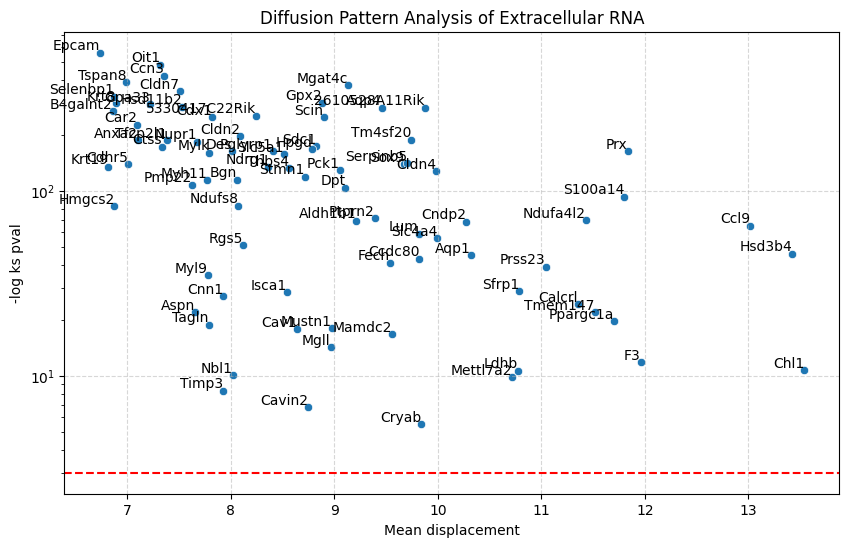

In [ ]:
troutpy.pl.diffusion_results(sdata, y_col='-log_ks_pval',y_logscale=True)

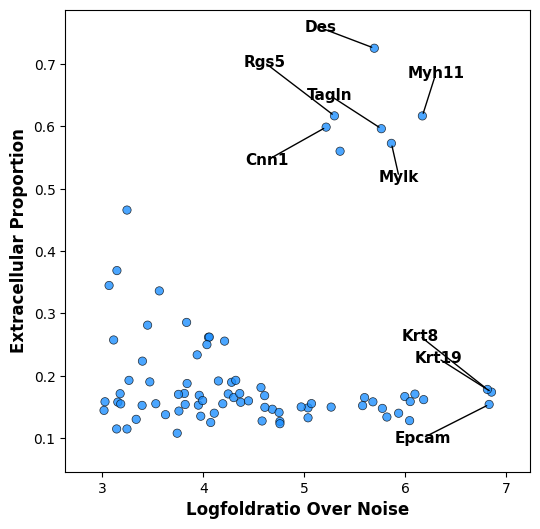

In [63]:
troutpy.pl.metric_scatter(sdata,
x_metric="logfoldratio_over_noise",
y_metric="extracellular_proportion",
label_top_n_x=3,label_top_n_y=6)

In [65]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False,n_bins=20)

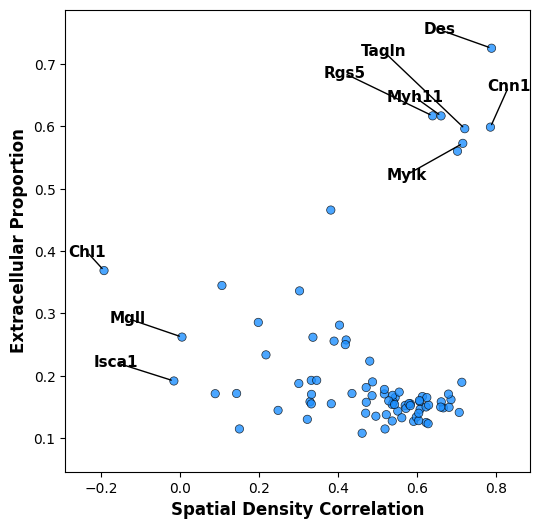

In [70]:
troutpy.pl.metric_scatter(sdata,
x_metric="spatial_density_correlation",
y_metric="extracellular_proportion",
label_top_n_x=0,label_top_n_y=6,label_bottom_n_x=3)

In [75]:
bottom_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation')['spatial_density_correlation'].keys()[0:6]
top_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=False)['spatial_density_correlation'].keys()[0:6]

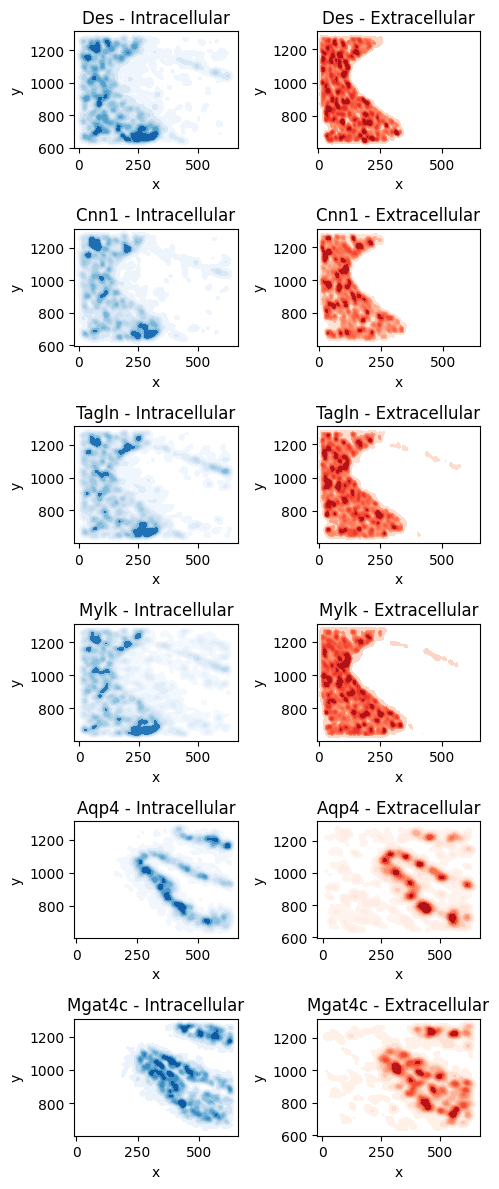

In [76]:
troutpy.pl.intra_extra_density(
    sdata, top_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,12)
)

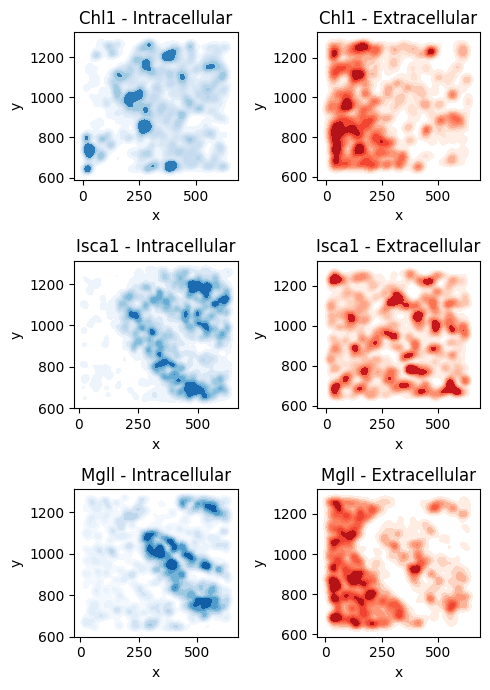

In [73]:
troutpy.pl.intra_extra_density(
    sdata, bottom_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,7)
)

In [77]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=3)

In [78]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False)

In [68]:
gen=sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Des,1718466,5.372709,0.0,0.420576,0.579424,-1.527242,0.794840,0.0,0.000002,0.0,0.559565,0.0,235.874054,0.898087,0.038660
Rgs5,1292465,5.087829,0.0,0.486830,0.513170,-1.259523,0.767295,0.0,0.000002,0.0,0.572803,0.0,114.919647,0.896741,0.045251
Myh11,2954152,5.914489,0.0,0.500571,0.499429,-1.204548,0.803042,0.0,0.000002,0.0,0.614265,0.0,175.079300,0.895307,0.043182
Cnn1,1095387,4.922385,0.0,0.514510,0.485490,-1.148774,0.752762,0.0,0.000002,0.0,0.605094,0.0,132.244095,0.919385,0.027027
Tagln,1883852,5.464596,0.0,0.519607,0.480393,-1.128365,0.776630,0.0,0.000002,0.0,0.617004,0.0,165.001114,0.906204,0.035734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pglyrp1,491612,4.121212,0.0,0.860886,0.139114,0.615838,0.403058,0.0,0.000002,0.0,0.478195,0.0,135.951080,0.964150,0.015897
5330417C22Rik,588109,4.300434,0.0,0.862925,0.137075,0.632968,0.400191,0.0,0.000002,0.0,0.506649,0.0,118.910728,0.962626,0.014965
Cldn4,175347,3.090289,0.0,0.863494,0.136506,0.637783,0.333075,0.0,0.000002,0.0,0.370564,0.0,71.764809,0.955798,0.016547
Ptprn2,200592,3.224795,0.0,0.870872,0.129128,0.701861,0.251532,0.0,0.000002,0.0,0.338198,0.0,142.429138,0.942986,0.017906


In [61]:
gen=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Mgll,435836,4.000788,0.0,0.758866,0.241134,-0.060361,0.489629,0.0,0.000002,0.0,0.340680,0.0,63.303387,0.636961,0.051766
Bgn,560456,4.252273,0.0,0.816630,0.183370,0.286846,0.344240,0.0,0.000002,0.0,0.300215,0.0,73.513901,0.767284,0.032882
Dpt,390914,3.892010,0.0,0.735840,0.264160,-0.182376,0.390313,0.0,0.000002,0.0,0.308351,0.0,163.018616,0.782256,0.039425
Chl1,215006,3.294188,0.0,0.652428,0.347572,-0.577102,0.388354,0.0,0.000002,0.0,0.201248,0.0,106.977654,0.782540,0.035466
Sfrp1,170556,3.062586,0.0,0.805794,0.194206,0.216077,0.255329,0.0,0.000002,0.0,0.253969,0.0,113.822319,0.791838,0.036108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oit1,1867761,5.456018,0.0,0.860657,0.139343,0.613923,0.492231,0.0,0.000002,0.0,0.667311,0.0,143.438889,0.969365,0.012514
Tfcp2l1,1468150,5.215280,0.0,0.830938,0.169062,0.385460,0.498740,0.0,0.000002,0.0,0.631032,0.0,71.777977,0.969914,0.010797
Cldn2,611131,4.338833,0.0,0.881705,0.118295,0.801840,0.429227,0.0,0.000002,0.0,0.580331,0.0,75.898804,0.972266,0.016874
Aqp4,177059,3.100005,0.0,0.809832,0.190168,0.242085,0.362197,0.0,0.000002,0.0,0.434927,0.0,17.113632,0.972980,0.019523


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f53b1ccc5b0>>
Traceback (most recent call last):
  File "/home/sergio/.local/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


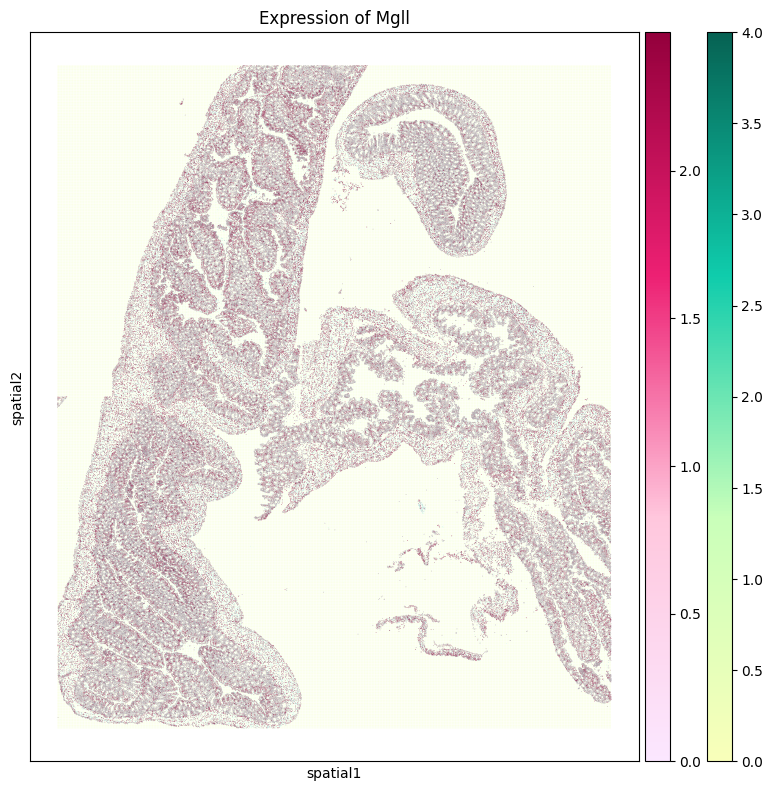

In [66]:
troutpy.pl.spatial_inout_expression(sdata,'Bgn',spot_size_cells=6,spot_size_extra=4)

## Signature analysis

In [ ]:
xenium_path_cropped = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata=sd.read_zarr(xenium_path_cropped)

In [ ]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,
    layer = "transcripts",
    gene_key = "feature_name",
    method = "bin", square_size=10,
)

In [153]:
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=20)
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_cells(adata, min_counts=200)


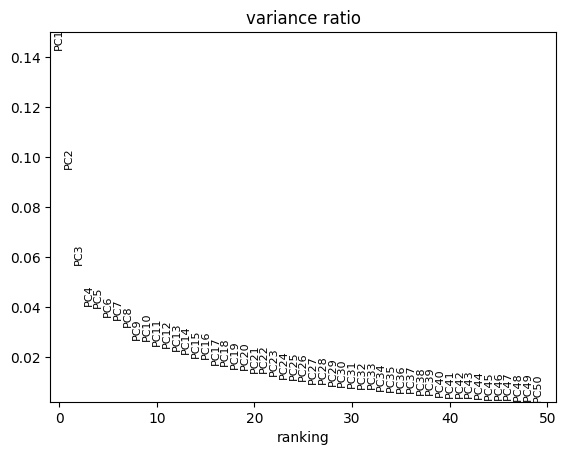

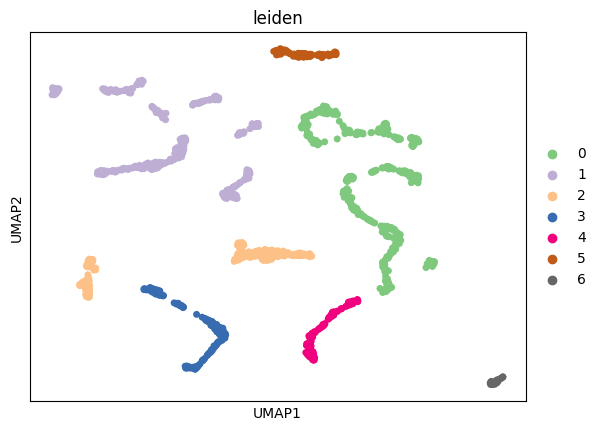

In [156]:

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50)
# neighbors
sc.pp.neighbors(adata,n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.01)
sc.pl.umap(adata,color='leiden',palette='Accent',s=100)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

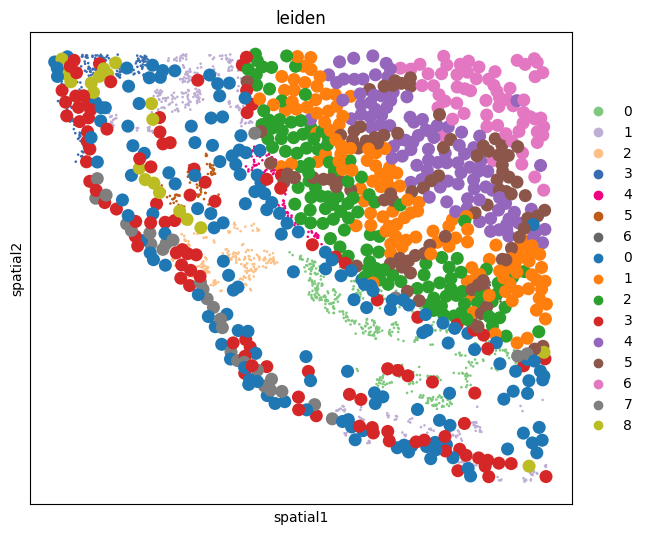

In [157]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=2,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=10,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

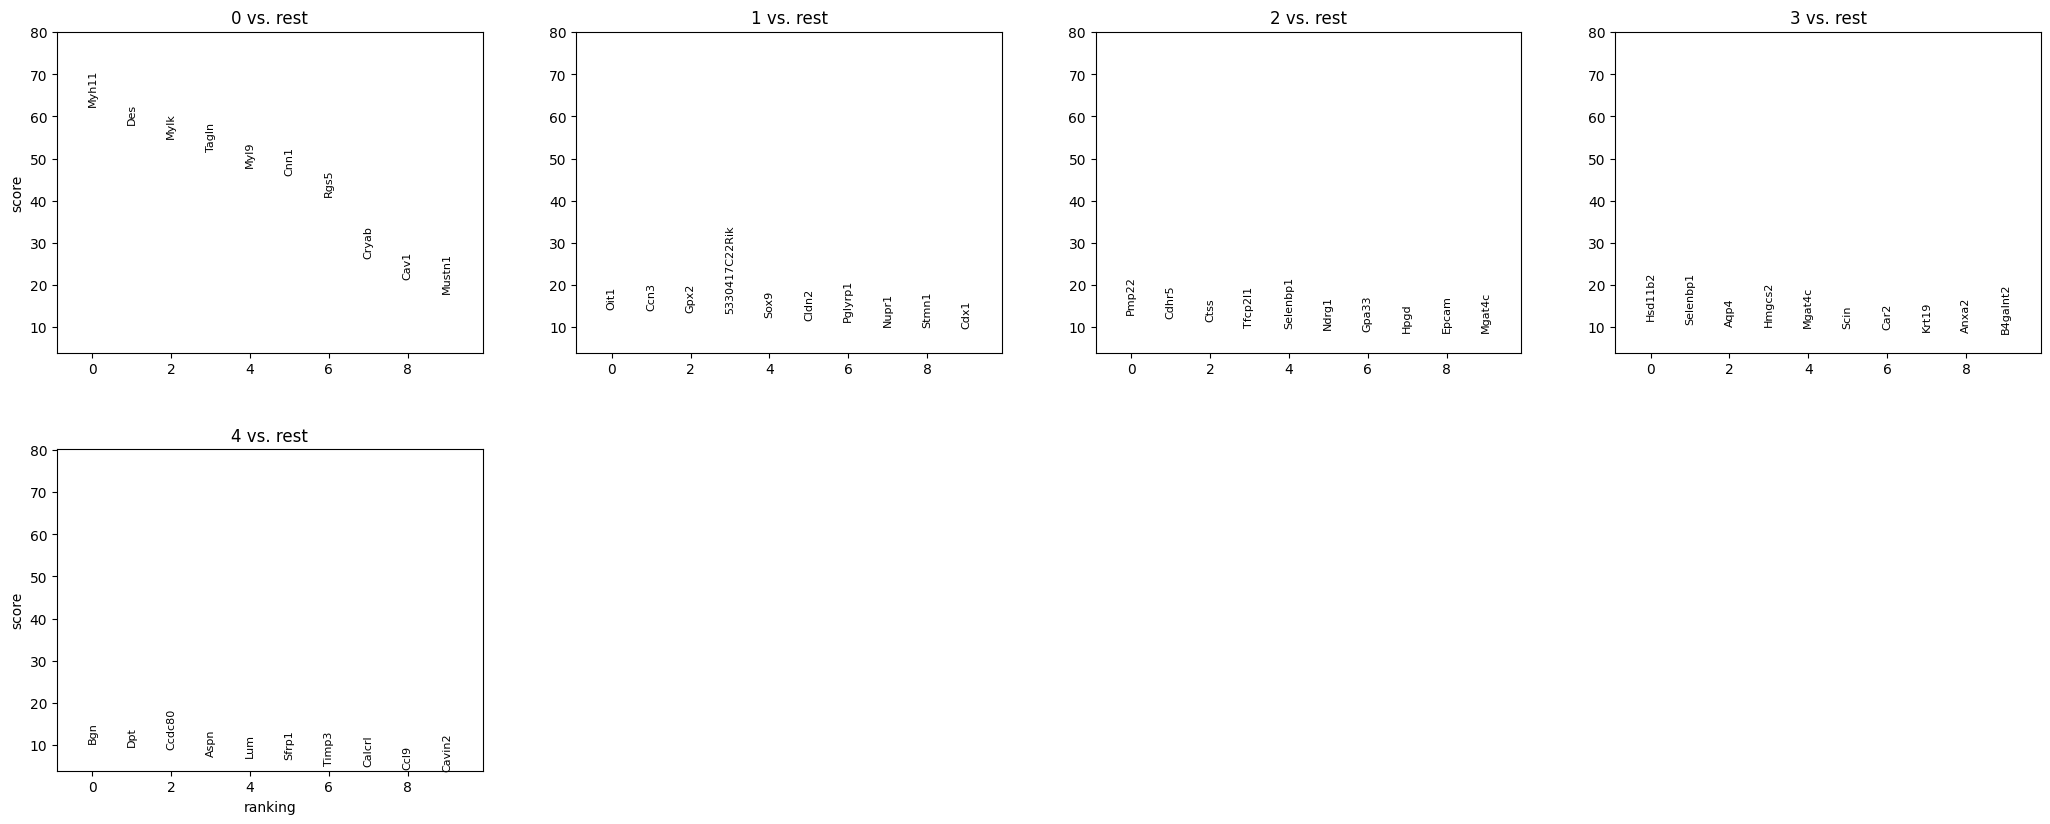

In [105]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups(adata,groupby='leiden',n_genes=10)

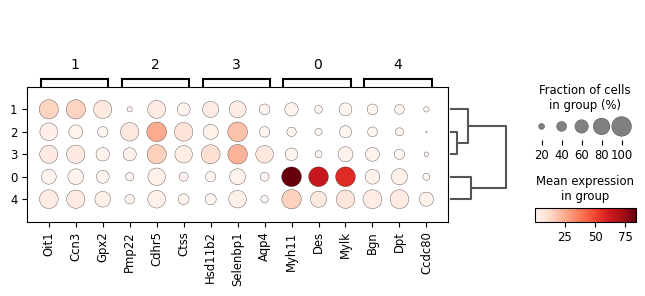

In [106]:
sc.pl.rank_genes_groups_dotplot(adata,groupby='leiden',n_genes=3)

In [107]:
troutpy.tl.latent_factor(sdata,method='NMF',layer='segmentation_free_table', n_components=10)

In [108]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer = "segmentation_free_table", cellular_layer='table')

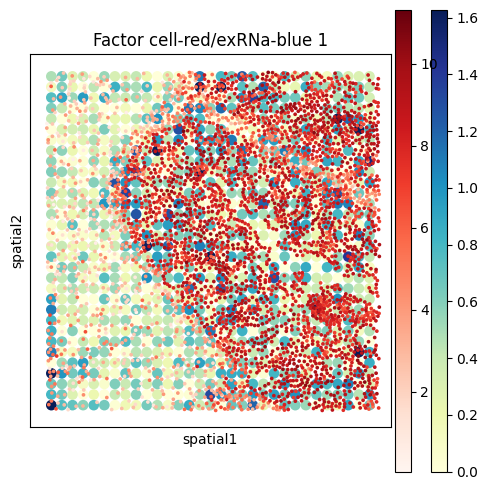

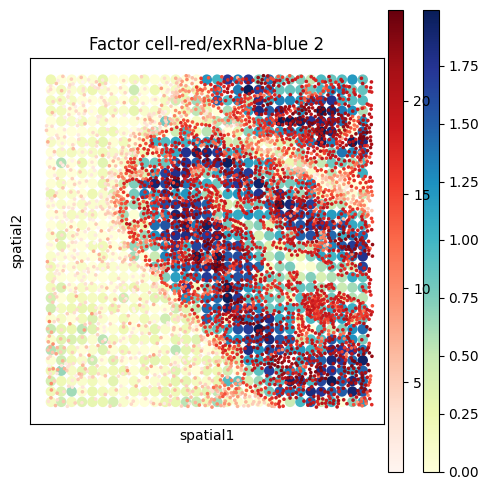

In [119]:
troutpy.pl.paired_nmf_factors(sdata,layer='segmentation_free_table',spot_size_exrna=20,spot_size_cells=7, figsize=(5, 5), n_factors=2)

[<Axes: title={'center': 'NNAT'}, xlabel='spatial1', ylabel='spatial2'>]

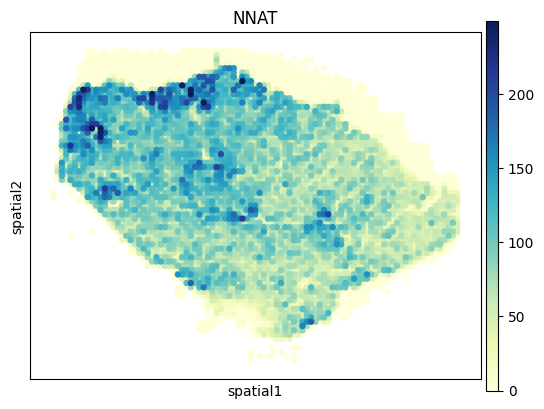

In [61]:
gene='NNAT'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

[<Axes: title={'center': 'MT-CO2'}, xlabel='spatial1', ylabel='spatial2'>]

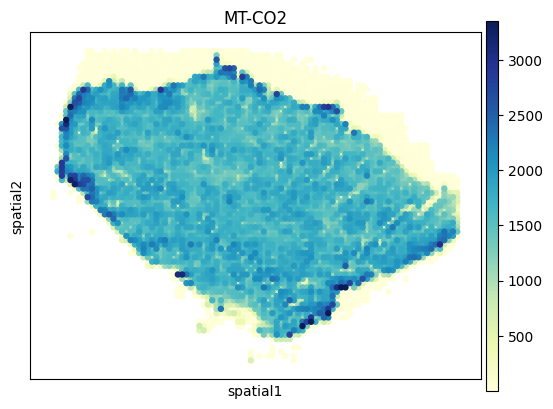

In [52]:
gene='MT-CO2'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

In [ ]:
sdata['xrna_metadata'].var.sort_values(by='moran_I',ascending=False).head(10)

In [35]:
troutpy.pl.nmf_gene_contributions(sdata, nmf_adata_key="segmentation_free_table", vmin=0.0, vmax=0.02, save=False, figsize=(4, 5))

KeyError: 'H_nmf'